**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [1]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [2]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [3]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [4]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [5]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  303.8  steps_to_475 200000  final  478.4  time  65.3 s
seed 1: auc  252.2  steps_to_475  78448  final  309.9  time  66.0 s
seed 2: auc  299.4  steps_to_475  66675  final  450.3  time  65.5 s
seed 3: auc  303.5  steps_to_475  95457  final  399.6  time  65.6 s
seed 4: auc  268.2  steps_to_475  69735  final  471.2  time  65.4 s
seed 0: auc  368.3  steps_to_475  67872  final  500.0  time  63.7 s
seed 1: auc  360.5  steps_to_475  97746  final  500.0  time  61.7 s
seed 2: auc  382.3  steps_to_475  66643  final  497.6  time  61.6 s
seed 3: auc  320.2  steps_to_475  74677  final  500.0  time  65.4 s
seed 4: auc  313.5  steps_to_475  84618  final  414.2  time  62.0 s
seed 0: auc  340.7  steps_to_475 141178  final  500.0  time  60.5 s
seed 1: auc  332.1  steps_to_475 146040  final  500.0  time  59.4 s
seed 2: auc  247.8  steps_to_475  76393  final  471.9  time  59.1 s
seed 3: auc  268.0  steps_to_475 200000  final  500.0  time  63.8 s
seed 4: auc  349.1  steps_to_475 106907  final  

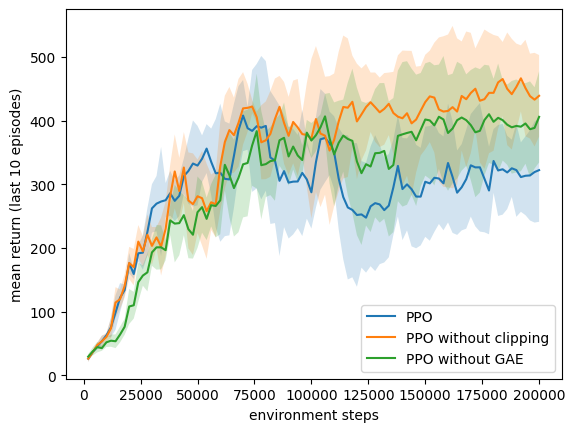

In [6]:
all_runs = {"PPO": run_seeds()}
all_runs["PPO without clipping"] = run_seeds({"clip_coef": 1e9})
all_runs["PPO without GAE"] = run_seeds({"gae_lambda": 1.0})
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

# Problem 3 (b): Preference tuning and RL in LLMs (OLMo 2 1B)

In [7]:
!pip install -q "lm-eval[ifeval]"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Setup

* The base model has no chat template, so it gets the plain prompts. The SFT, DPO and Instruct models get the chat template
  (the homework asks for this). For GSM8K, the 5 examples are then given as earlier turns of the chat (`fewshot_as_multiturn`).
* All models use the same examples (`limit=200` takes the first 200), the same few-shot examples and greedy decoding (the
  default of each task), so the only difference is the checkpoint and the chat template.
* `float16`, because the T4 GPU does not support `bfloat16`.

In [8]:
import gc
import json
import torch
import lm_eval

MODELS = {
    "Base":     ("allenai/OLMo-2-0425-1B", False),          # (Hugging Face name, use the chat template)
    "SFT":      ("allenai/OLMo-2-0425-1B-SFT", True),
    "DPO":      ("allenai/OLMo-2-0425-1B-DPO", True),
    "Instruct": ("allenai/OLMo-2-0425-1B-Instruct", True),
}
TASKS = ["gsm8k", "ifeval", "truthfulqa_mc2"]
LIMIT = 200
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## Run the benchmarks

One call of `lm_eval.simple_evaluate` for each checkpoint. Each result is saved to a JSON file,
so a crash later does not lose it. On a T4 this takes roughly 15–25 minutes per checkpoint (an estimate).

In [9]:
all_results = {}

for name in MODELS:
    hf_name, chat = MODELS[name]
    print("=== Evaluating", name)
    out = lm_eval.simple_evaluate(
        model="hf",
        model_args="pretrained=" + hf_name + ",dtype=float16",
        tasks=TASKS,
        limit=LIMIT,
        batch_size=16,
        apply_chat_template=chat,
        fewshot_as_multiturn=chat,
        log_samples=True,
    )
    all_results[name] = {"results": out["results"], "samples": out["samples"]}
    with open("results_" + name + ".json", "w") as f:
        json.dump(all_results[name], f, default=str)
    # free the GPU memory before the next checkpoint
    del out
    gc.collect()
    torch.cuda.empty_cache()

=== Evaluating Base


config.json:   0%|          | 0.00/623 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.34k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.14M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/14.9k [00:00<?, ?B/s]

... (49 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

Running loglikelihood requests: 100%|██████████| 1476/1476 [00:46<00:00, 31.44it/s]
fatal: not a git repository (or any parent up to mount point /kaggle)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).


## Results table

* **GSM8K**: exact match of the final number. *strict* needs the answer in the format `#### 42` (the format of the few-shot
  examples); *flexible* takes the last number in the response. Chat models often do not copy the `####` format,
  so *flexible* is the fairer comparison.
* **IFEval**: *prompt-level* = all instructions of a prompt are followed; *instruction-level* = fraction of single instructions
  that are followed (strict version).
* **TruthfulQA MC2**: the probability that the model gives to the true answers.

In [10]:
for name in all_results:
    r = all_results[name]["results"]
    print(name)
    print("GSM8K strict:       ", round(100 * r["gsm8k"]["exact_match,strict-match"], 1))
    print("GSM8K flexible:     ", round(100 * r["gsm8k"]["exact_match,flexible-extract"], 1))
    print("IFEval prompt-level:", round(100 * r["ifeval"]["prompt_level_strict_acc,none"], 1))
    print("IFEval instr.-level:", round(100 * r["ifeval"]["inst_level_strict_acc,none"], 1))
    print("TruthfulQA MC2:     ", round(100 * r["truthfulqa_mc2"]["acc,none"], 1))

Base
  GSM8K strict:        30.5
  GSM8K flexible:      30.5
  IFEval prompt-level: 9.5
  IFEval instr.-level: 19.8
  TruthfulQA MC2:      38.8
SFT
  GSM8K strict:        32.0
  GSM8K flexible:      39.0
  IFEval prompt-level: 40.5
  IFEval instr.-level: 53.8
  TruthfulQA MC2:      44.8
DPO
  GSM8K strict:        48.0
  GSM8K flexible:      52.5
  IFEval prompt-level: 54.0
  IFEval instr.-level: 67.9
  TruthfulQA MC2:      46.6
Instruct
  GSM8K strict:        54.0
  GSM8K flexible:      61.0
  IFEval prompt-level: 58.5
  IFEval instr.-level: 70.1
  TruthfulQA MC2:      48.6


## Example outputs

The same prompts for all four checkpoints. For GSM8K, I show the response to one question; for IFEval, the response to one
instruction. The texts are cut after 600 characters.

In [11]:
def get_response(name, task, doc_index):
    for s in all_results[name]["samples"][task]:
        if s["doc_id"] == doc_index:
            return s["resps"][0][0]
    return None


def show_example(task, doc_index, question_key):
    doc = None
    for s in all_results["Base"]["samples"][task]:
        if s["doc_id"] == doc_index:
            doc = s["doc"]
            break
    print("##########", task, "example", doc_index)
    print("PROMPT:", doc[question_key])
    if task == "gsm8k":
        print("TRUE ANSWER:", doc["answer"].split("####")[-1].strip())
    for name in all_results:
        print("----------", name)
        print(get_response(name, task, doc_index)[:600])
    print()


show_example("gsm8k", 0, "question")
show_example("gsm8k", 1, "question")
show_example("ifeval", 0, "prompt")
show_example("ifeval", 5, "prompt")

########## gsm8k example 0
PROMPT: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
TRUE ANSWER: 18
---------- Base
 Janet eats 3 * 7 = <<3*7=21>>21 duck eggs per week.
She sells the remainder at the farmers' market daily for $2 per fresh duck egg, so she makes 16 * 7 = $<<16*7=112>>112 per week.
Therefore, she makes $112 / 7 = $<<112/7=16>>16 per day at the farmers' market.
#### 16
---------- SFT
She eats 3 eggs for breakfast and bakes 4 muffins, so she uses 3 + 4 = <<3+4=7>>7 eggs per day.
She has 16 - 7 = <<16-7=9>>9 eggs left to sell.
She sells each egg for $2, so she makes 9 x 2 = $<<9*2=18>>18 per day.
#### 18
---------- DPO
First, we need to determine how many eggs Janet doesn’t eat or use for baking. She starts with 16 eggs and eats 3 for breakfast, 

## Diversity of the outputs

Greedy decoding gives one answer per prompt, so it cannot show diversity. Here I sample 5 responses at temperature 1.0
for each of the first 20 GSM8K questions (no few-shot examples), with the same prompt for every checkpoint
(plain text for the base model, the chat template for the others). For each question I count:

* the number of **different final answers** among the 5 samples (1 = always the same answer),
* the fraction of the 5 samples with the **correct** answer.

A model whose answers collapse to one mode has few different answers. If it is also often right, the
collapse is not a problem for accuracy, but it is less diverse.

In [13]:
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

questions = load_dataset("openai/gsm8k", "main", split="test").select(range(20))
N_SAMPLES = 5


def last_number(text):
    answer = None
    for word in text.replace(",", "").replace("$", "").split():
        word = word.strip(".:;!?()*")
        try:
            float(word)
            answer = word
        except ValueError:
            pass
    return answer


def sample_answers(hf_name, chat):
    tokenizer = AutoTokenizer.from_pretrained(hf_name)
    model = AutoModelForCausalLM.from_pretrained(hf_name, torch_dtype=torch.float16).to("cuda")
    torch.manual_seed(0)
    n_different = []
    frac_correct = []
    for q in questions:
        if chat:
            messages = [{"role": "user", "content": q["question"]}]
            prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
            ids = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).input_ids
        else:
            ids = tokenizer("Question: " + q["question"] + "\nAnswer:", return_tensors="pt").input_ids
        ids = ids.to("cuda")
        with torch.no_grad():
            out = model.generate(ids, do_sample=True, temperature=1.0, max_new_tokens=256,
                                 num_return_sequences=N_SAMPLES, pad_token_id=tokenizer.eos_token_id)
        true_answer = q["answer"].split("####")[-1].strip().replace(",", "")
        answers = []
        n_correct = 0
        for seq in out:
            text = tokenizer.decode(seq[ids.shape[1]:], skip_special_tokens=True)
            text = text.split("Question:")[0]
            answer = last_number(text)
            answers.append(answer)
            if answer == true_answer:
                n_correct += 1
        n_different.append(len(set(answers)))
        frac_correct.append(n_correct / N_SAMPLES)
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return sum(n_different) / len(n_different), sum(frac_correct) / len(frac_correct)


for name in MODELS:
    hf_name, chat = MODELS[name]
    n_diff, correct = sample_answers(hf_name, chat)
    print(name, "  different answers (of 5):", round(n_diff, 2),
          "  correct samples:", round(100 * correct, 1), "%")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

Base   different answers (of 5): 4.65   correct samples: 2.0 %


Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

SFT   different answers (of 5): 3.15   correct samples: 30.0 %


Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

DPO   different answers (of 5): 2.75   correct samples: 37.0 %


Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

Instruct   different answers (of 5): 2.8   correct samples: 43.0 %


# Bonus Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

In [14]:
def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    #A copy of train_ppo. The new lines are marked with NEW.
    cfg = {**CONFIG, **(cfg or {})}
    #NEW (ablation)
    critic_only = "critic_only" in cfg
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N = cfg["num_envs"]
    T = cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4)
    actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N)
    rewards = torch.zeros(T, N)
    dones = torch.zeros(T, N)
    values = torch.zeros(T, N)
    #NEW
    boot = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t] = next_obs
            dones[t] = next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t] = a
            logps[t] = logp
            values[t] = v
            #NEW
            o, r, term, trunc, final_obs = envs.step(a.numpy())     
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
            #NEW
            boot[t] = 0.0
            for i in range(N):
                if trunc[i] and not term[i]:
                    with torch.no_grad():
                        v_last = agent.get_value(torch.tensor(final_obs[i], dtype=torch.float32))
                    boot[t, i] = cfg["gamma"] * v_last
        with torch.no_grad():
            next_value = agent.get_value(next_obs)
            #NEW
            adv, returns = compute_gae(rewards + boot, values, dones, next_value, next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
            if critic_only:
                #NEW (ablation)
                adv, _ = compute_gae(rewards, values, dones, next_value, next_done,
                                     cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        ppo_update(agent, opt, b, cfg)
    return agent, envs.episodes, time.time() - start

seed 0: auc  303.8  steps_to_475 182157  final  500.0  time  60.9 s
seed 1: auc  356.1  steps_to_475 116098  final  500.0  time  60.1 s
seed 2: auc  341.8  steps_to_475  95473  final  500.0  time  61.2 s
seed 3: auc  317.6  steps_to_475 148377  final  500.0  time  60.1 s
seed 4: auc  281.3  steps_to_475  90196  final  200.6  time  62.0 s
PPO                      auc  285.4 +-  21.3  steps_to_475   102063 (4/5 runs)  final  421.9 +-  62.4  time  65.6 s
Time-limit bootstrap     auc  320.1 +-  26.6  steps_to_475   126460 (5/5 runs)  final  440.1 +- 119.8  time  60.9 s


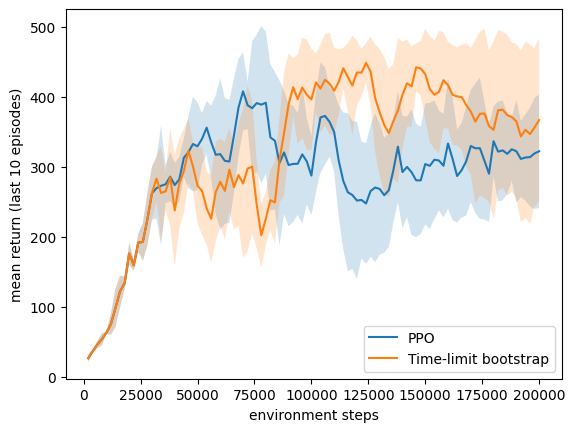

In [15]:
bootstrap_runs = run_seeds(train_fn=my_train_ppo)
summarize(all_runs["PPO"], "PPO")
summarize(bootstrap_runs, "Time-limit bootstrap")
plot_curves({"PPO": all_runs["PPO"], "Time-limit bootstrap": bootstrap_runs})

seed 0: auc  319.5  steps_to_475 102771  final  338.1  time  66.6 s
seed 1: auc  350.4  steps_to_475 116478  final  500.0  time  66.6 s
seed 2: auc  300.2  steps_to_475  86372  final  442.4  time  68.8 s
seed 3: auc  283.2  steps_to_475 200000  final  491.4  time  65.2 s
seed 4: auc  238.3  steps_to_475 200000  final  474.9  time  64.6 s
PPO                      auc  285.4 +-  21.3  steps_to_475   102063 (4/5 runs)  final  421.9 +-  62.4  time  65.6 s
Time-limit bootstrap     auc  320.1 +-  26.6  steps_to_475   126460 (5/5 runs)  final  440.1 +- 119.8  time  60.9 s
Ablation: critic only    auc  298.3 +-  37.4  steps_to_475   141124 (3/5 runs)  final  449.3 +-  59.0  time  66.4 s


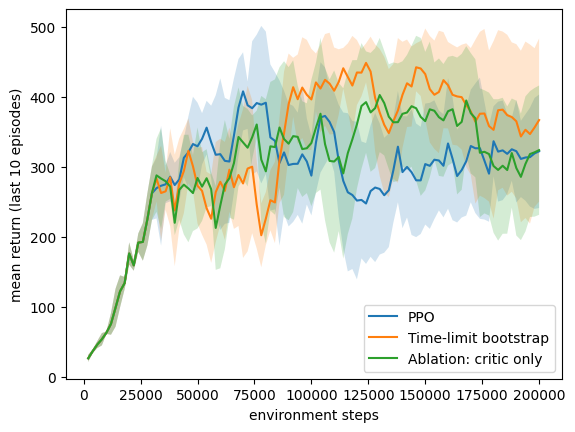

In [16]:
ablation_runs = run_seeds({"critic_only": True}, train_fn=my_train_ppo)
summarize(all_runs["PPO"], "PPO")
summarize(bootstrap_runs, "Time-limit bootstrap")
summarize(ablation_runs, "Ablation: critic only")
plot_curves({"PPO": all_runs["PPO"], "Time-limit bootstrap": bootstrap_runs,
             "Ablation: critic only": ablation_runs})

In [17]:
KL_TARGET = 0.01 #the target KL between the old and the new policy for one update 


def ppo_update_kl(agent, opt, b, cfg, beta):
    # A copy of ppo_update
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    kls = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            log_ratio = logp - b["logp"][mb]
            ratio = log_ratio.exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = (-adv * ratio).mean()
            #NEW: no clipping
            kl = ((ratio - 1) - log_ratio).mean()            
            #NEW: estimate of KL(pi_old || pi_theta)
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss + beta * kl - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            kls.append(kl.item())
    return np.mean(kls)


def my_train_ppo_kl(seed, cfg=None):
    # A copy of train_ppo. The new lines are marked with NEW.
    cfg = CONFIG                      
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N = cfg["num_envs"]
    T = cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4)
    actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N)
    rewards = torch.zeros(T, N)
    dones = torch.zeros(T, N)
    values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    beta = 1.0                         
    #NEW: the starting weight of the KL penalty
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t] = next_obs
            dones[t] = next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t] = a
            logps[t] = logp
            values[t] = v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        kl = ppo_update_kl(agent, opt, b, cfg, beta)     # NEW
        # NEW: change beta
        if kl < KL_TARGET / 1.5:
            beta = beta / 2
        elif kl > KL_TARGET * 1.5:
            beta = beta * 2
    return agent, envs.episodes, time.time() - start


seed 0: auc  356.8  steps_to_475  62741  final  473.3  time  61.1 s
seed 1: auc  355.1  steps_to_475  67499  final  500.0  time  61.2 s
seed 2: auc  335.9  steps_to_475 126142  final  500.0  time  60.8 s
seed 3: auc  372.7  steps_to_475  89747  final  500.0  time  61.1 s
seed 4: auc  378.1  steps_to_475  82388  final  500.0  time  60.8 s
PPO                      auc  285.4 +-  21.3  steps_to_475   102063 (4/5 runs)  final  421.9 +-  62.4  time  65.6 s
PPO without clipping     auc  349.0 +-  27.2  steps_to_475    78311 (5/5 runs)  final  482.4 +-  34.1  time  62.9 s
PPO with KL penalty      auc  359.7 +-  14.9  steps_to_475    85703 (5/5 runs)  final  494.7 +-  10.7  time  61.0 s


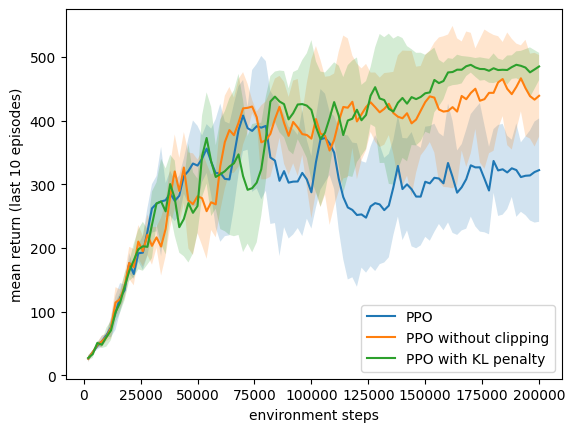

In [18]:
kl_runs = run_seeds(train_fn=my_train_ppo_kl)
summarize(all_runs["PPO"], "PPO")
summarize(all_runs["PPO without clipping"], "PPO without clipping")
summarize(kl_runs, "PPO with KL penalty")
plot_curves({"PPO": all_runs["PPO"], "PPO without clipping": all_runs["PPO without clipping"],
             "PPO with KL penalty": kl_runs})